## ⚙️ Load the GROMACS–PLUMED Environment

Loads the required **compiler, MPI, CUDA, GROMACS, and PLUMED environment** on ACCRE and makes the configured GROMACS–PLUMED installation available within the notebook for subsequent HREMD setup and simulations.

In [1]:
import sys
!{sys.executable} -m pip install plumed

Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
  Using cached plumed-2.10.0-cp312-cp312-linux_x86_64.whl


In [2]:
import plumed

In [1]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [2]:
load_gmx_plumed()

Notice that we use two temperature groups (protein and solvent). However, when we will do solute tempering, both temperatures will be equal to 300K

## 2a: Setting up scaled Hamiltonians

In [5]:
import os
import re
import subprocess

def run_cmd(cmd):
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

workdir = os.getcwd()

input_gro = os.path.join(workdir, "Prep/b4md.gro")
input_top = os.path.join(workdir, "Prep/protein.top")
input_mdp = os.path.join(workdir, "grompp.mdp")

os.makedirs("2a", exist_ok=True)

# ============================================================
# Generate self-contained topology
# ============================================================

run_cmd(
    f"gmx_mpi grompp "
    f"-f {input_mdp} "
    f"-c {input_gro} "
    f"-p {input_top} "
    f"-pp 2a/processed.top "
    f"-o 2a/test.tpr"
)

# ============================================================
# Mark first molecule atoms with "_"
# ============================================================

in_molecules = False
in_atoms = False
molecule_done = False

with open("2a/processed.top") as f, \
     open("2a/processed_selected.top","w") as ff:

    for l in f:

        if (
            in_atoms
            and not re.match(r" *;.*",l)
            and not re.match(r"\[.*",l)
            and len(l.split()) > 2
        ):

            ll = l.split()
            ll[1] = ll[1] + "_"
            print(" ".join(ll), file=ff)

        else:
            print(l, end="", file=ff)

        if not molecule_done and re.match(r"\[ *moleculetype *\]",l):
            in_molecules = True
            molecule_done = True

        elif in_molecules and re.match(r"\[ *atoms *\]",l):
            in_atoms = True

        elif re.match(r"\[.*",l):
            in_molecules = False
            in_atoms = False

# ============================================================
# Generate scaled topologies
# ============================================================

run_cmd(
    "cd 2a && "
    "plumed partial_tempering 1.0 "
    "< processed_selected.top "
    "> scaled1.0.top"
)

run_cmd(
    "cd 2a && "
    "plumed partial_tempering 0.5 "
    "< processed_selected.top "
    "> scaled0.5.top"
)

print("\n🎉 Finished Exercise 2a.")

gmx_mpi grompp -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONI/grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONI/Prep/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONI/Prep/protein.top -pp 2a/processed.top -o 2a/test.tpr


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Setting the LD random seed to -1771114497

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   275    Protein residues
There are: 13626      Water residues
There are:     3        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.428 nm between atom 2048 and 2056

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 310 K

Calculated rlist for 1x1 atom pair-list as 0.936 nm, buffer size 0.036 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions 

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

cd 2a && plumed partial_tempering 0.5 < processed_selected.top > scaled0.5.top


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


🎉 Finished Exercise 2a.


In [7]:
!diff 2a/scaled1.0.top 2a/scaled0.5.top

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

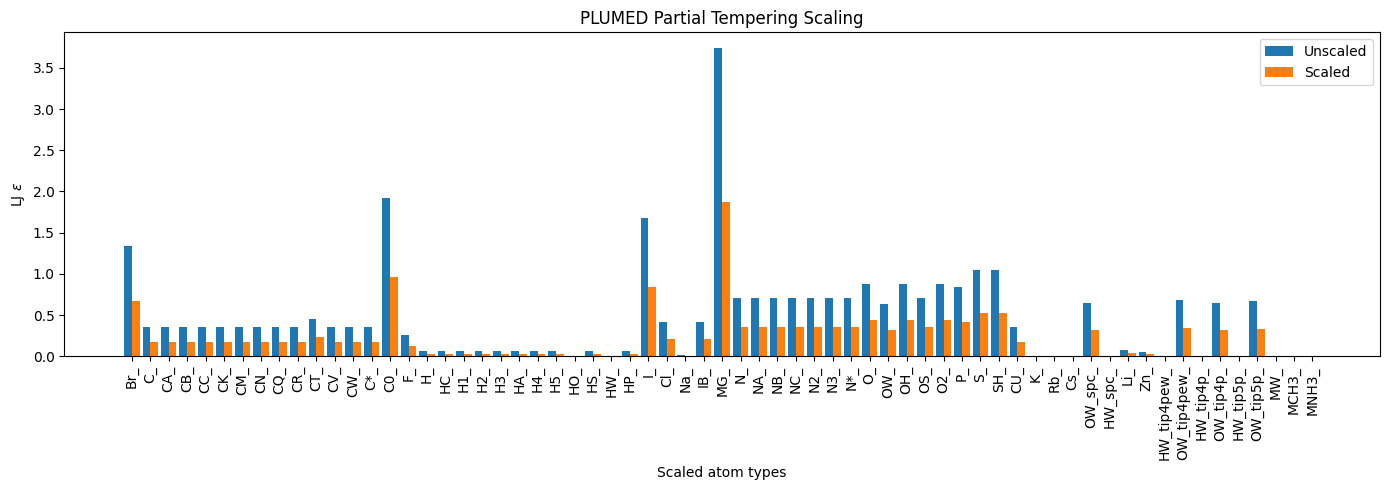

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def read_scaled_eps(topfile):

    rows = []

    with open(topfile) as f:

        for line in f:

            if "scaled" not in line:
                continue

            line = line.split(";")[0]

            parts = line.split()

            if len(parts) < 7:
                continue

            atom = parts[0]
            eps = float(parts[6])

            rows.append([atom, eps])

    return pd.DataFrame(
        rows,
        columns=["atom","epsilon"]
    )

top1 = read_scaled_eps("2a/scaled1.0.top")
top05 = read_scaled_eps("2a/scaled0.5.top")

df = top1.merge(
    top05,
    on="atom",
    suffixes=("_1.0","_0.5")
)

x = np.arange(len(df))

width = 0.42

plt.figure(figsize=(14,5))

plt.bar(
    x-width/2,
    df["epsilon_1.0"],
    width,
    label="Unscaled"
)

plt.bar(
    x+width/2,
    df["epsilon_0.5"],
    width,
    label="Scaled"
)

plt.xticks(
    x,
    df["atom"],
    rotation=90
)

plt.ylabel(r"LJ $\epsilon$")
plt.xlabel("Scaled atom types")

plt.title(
    "PLUMED Partial Tempering Scaling"
)

plt.legend()

plt.tight_layout()
plt.show()

# 2b: Sanity check on generated topologies

In [9]:
import os
import subprocess

def run_cmd(cmd):
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

# ============================================================
# Exercise 2b: short reference trajectory sanity check
# ============================================================

os.makedirs("2b", exist_ok=True)

run_cmd(
    "cd 2b && "
    "gmx_mpi grompp "
    "-f ../grompp.mdp "
    "-c ../b4md.gro "
    "-p ../topol.top "
    "-o topol.tpr"
)

run_cmd(
    "cd 2b && "
    "gmx_mpi mdrun "
    "-deffnm topol "
    "-nsteps 5000"
)

print("\n🎉 Finished Exercise 2b reference trajectory.")

cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p ../topol.top -o topol.tpr


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Setting the LD random seed to -42008577

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimen

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


🎉 Finished Exercise 2b reference trajectory.


### 🔍 Exercise 2b — Sanity Check

Recompute energies for the **same trajectory** using:

1. Original topology
2. `partial_tempering(1.0)` topology

```text
Same coordinates
+
Different topology files
↓
Compare energies
```



In [10]:
import os
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

os.makedirs("2b/rerun0",exist_ok=True)
os.makedirs("2b/rerun1",exist_ok=True)

run("cp 2a/processed_selected.top 2b/processed_selected.top")

run("cd 2b && plumed partial_tempering 1.0 < processed_selected.top > topol_scaled1.0.top")

run("cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr")

run("cd 2b/rerun0 && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol.tpr")

run('cd 2b/rerun0 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

run("cd 2b/rerun1 && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled1.0.tpr")

run('cd 2b/rerun1 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

print("🎉 Finished sanity check")

cp 2a/processed_selected.top 2b/processed_selected.top
cd 2b && plumed partial_tempering 1.0 < processed_selected.top > topol_scaled1.0.top
cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b
Command line:
  gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file ../grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "I Caught It In the Face" (P.J. Harvey)



Setting the LD random seed to -25952772

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimen

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b/rerun0
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol.tpr

Reading file ../topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 80, rlist from 0.9 to 1.039


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the GPU
Using 1 MPI proce

cd 2b/rerun0 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no


...


Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3333.92         --    71.7587    77.7358  (kJ/mol)
Angle                       9361.48         --    107.351    225.635  (kJ/mol)
Proper Dih.                 10421.7         --    51.6824   -124.571  (kJ/mol)
Per. Imp. Dih.              519.309         --    20.6218   -8.61691  (kJ/mol)
LJ-14                       4448.28         --    19.9374   -45.7583  (kJ/mol)
Coulomb-14                  53570.5         --    86.8731   -197.777  (kJ/mol)
LJ (SR)                     71667.9         --    364.246   -711.555  (kJ/mol)
Disper. corr.              -7822.41         --          0          0  (kJ/mol)
Coulomb (SR)                -687426         --    575.349    237.375  (kJ/mol)
Coul. recip.             

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b/rerun1
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled1.0.tpr

Reading file ../topol_scaled1.0.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 80, rlist from 0.9 to 1.039


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the G

cd 2b/rerun1 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b/rerun1
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "It's just the way this stuff is done" (Built to Spill)




Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3333.92         --    71.7587    77.7358  (kJ/mol)
Angle                       9361.48         --    107.351    225.635  (kJ/mol)
Proper Dih.                 10421.7         --    51.6824   -124.571  (kJ/mol)
Per. Imp. Dih.              519.309         --    20.6218   -8.61691  (kJ/mol)
LJ-14                       4448.28         --    19.9374   -45.7583  (kJ/mol)
Coulomb-14                  53570.5         --    86.8731   -197.777  (kJ/mol)
LJ (SR)                     71667.9         --    364.258   -711.523  (kJ/mol)
Disper. corr.              -7822.41         --          0          0  (kJ/mol)
Coulomb (SR)                -687426         --    575.664    237.938  (kJ/mol)
Coul. recip.             

Expected:

```text
Original − Scaled(1.0) ≈ 0
```

Tiny numerical noise is normal.

Confirms:

✅ `partial_tempering` edited the topology correctly  
✅ No force field terms were accidentally changed  
✅ Hamiltonian remains unchanged at λ = 1.0

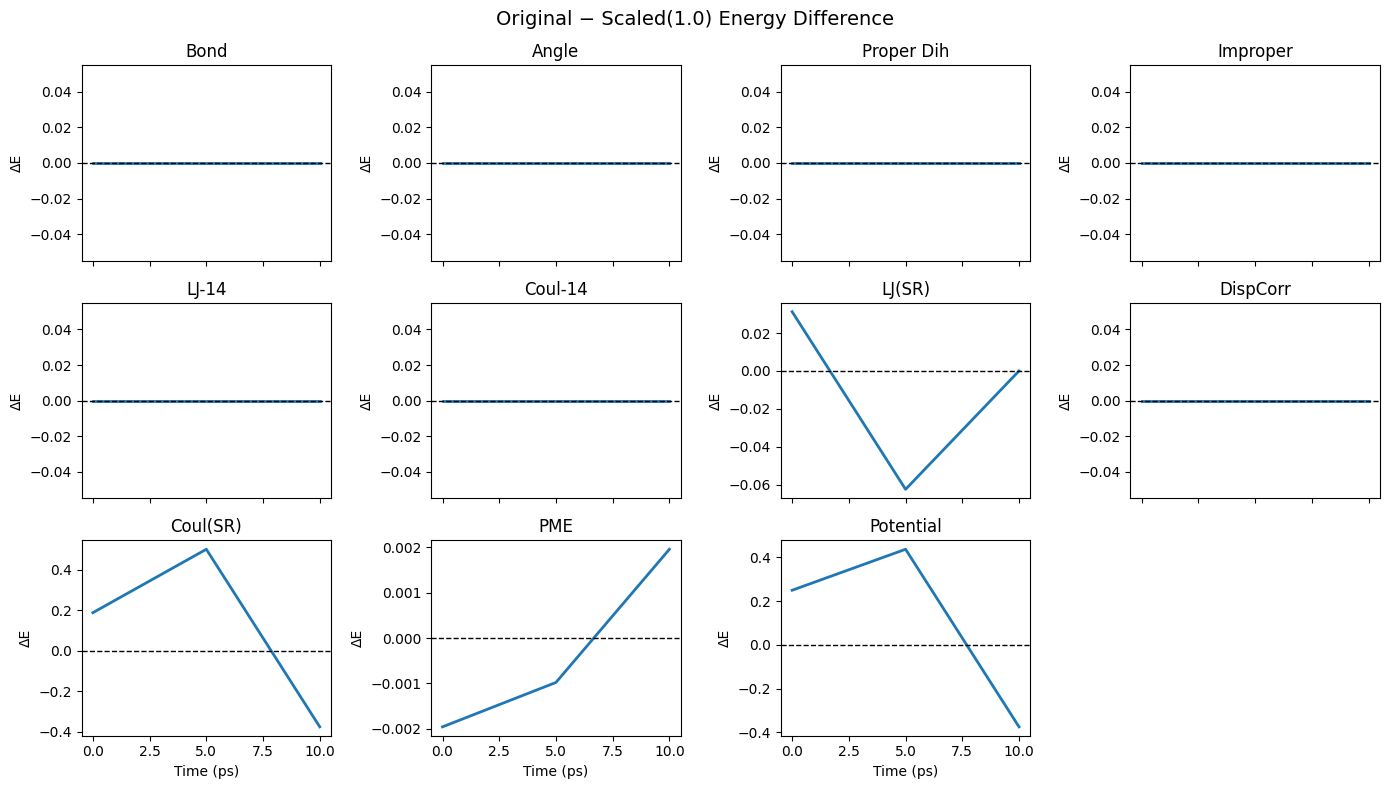

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Bond", "Angle", "Proper Dih", "Improper",
    "LJ-14", "Coul-14", "LJ(SR)", "DispCorr",
    "Coul(SR)", "PME", "Potential"
]

ene = pd.read_csv("2b/rerun0/energy.xvg", header=None, sep=r"\s+")
ene_scaled = pd.read_csv("2b/rerun1/energy.xvg", header=None, sep=r"\s+")

time = ene.iloc[:, 0]
diff = ene.iloc[:, 1:].values - ene_scaled.iloc[:, 1:].values

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
axes = axes.flatten()

for i, name in enumerate(labels):
    axes[i].plot(time, diff[:, i], lw=2)
    axes[i].axhline(0, color="black", ls="--", lw=1)
    axes[i].set_title(name)
    axes[i].set_ylabel("ΔE")

for j in range(len(labels), len(axes)):
    axes[j].axis("off")

for ax in axes[-4:]:
    ax.set_xlabel("Time (ps)")

fig.suptitle("Original − Scaled(1.0) Energy Difference", fontsize=14)
plt.tight_layout()
plt.show()

### 🔍 Whole-System Scaling Check

Select all atoms (protein + water + ions), apply:

```text
partial_tempering(0.1)
```

Then recompute energies on the **same trajectory** using `-rerun`.

Expected:

```text
Dihedral ≈ 0.1×
LJ ≈ 0.1×
Coulomb ≈ 0.1×
```

Confirms:

✅ Whole-system Hamiltonian scaling works correctly

In [12]:
import os
import re
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(cmd, shell=True, executable="/bin/bash", check=True)

os.makedirs("2b/rerun_whole", exist_ok=True)

# mark ALL moleculetype [ atoms ] sections with "_"
with open("2a/processed.top") as f, open("2b/processed_selected_whole.top", "w") as ff:

    in_atoms = False

    for l in f:

        if in_atoms and not re.match(r" *;.*", l) and not re.match(r"\[.*", l) and len(l.split()) > 2:
            ll = l.split()
            ll[1] = ll[1] + "_"
            print(" ".join(ll), file=ff)
        else:
            print(l, end="", file=ff)

        if re.match(r"\[ *atoms *\]", l):
            in_atoms = True
        elif re.match(r"\[.*", l):
            in_atoms = False

run("cd 2b && plumed partial_tempering 0.1 < processed_selected_whole.top > topol_scaled_whole0.1.top")

run("cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr")

run("cd 2b/rerun_whole && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled_whole0.1.tpr")

run('cd 2b/rerun_whole && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

print("🎉 Finished whole-system 0.1 scaling sanity check")

cd 2b && plumed partial_tempering 0.1 < processed_selected_whole.top > topol_scaled_whole0.1.top
cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b
Command line:
  gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file ../grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "I spent a lot of money on booze, birds a

Setting the LD random seed to -269619463

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.900 nm, buffer size 0.000 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b/rerun_whole
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled_whole0.1.tpr

Reading file ../topol_scaled_whole0.1.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 100, rlist from 0.9 to 0.9


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all 

cd 2b/rerun_whole && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2b/rerun_whole
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "When using an abacus, a human can achieve about 0.1 flops/watt. Super-computers achieve about 


Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3333.92         --    71.7587    77.7358  (kJ/mol)
Angle                       9361.48         --    107.351    225.635  (kJ/mol)
Proper Dih.                 1042.17         --    5.16843   -12.4576  (kJ/mol)
Per. Imp. Dih.              51.9309         --    2.06217  -0.861671  (kJ/mol)
LJ-14                       444.828         --    1.99373   -4.57578  (kJ/mol)
Coulomb-14                  5357.06         --    8.68777   -19.7788  (kJ/mol)
LJ (SR)                      7166.8         --    36.4404   -71.1816  (kJ/mol)
Disper. corr.              -782.241         --          0          0  (kJ/mol)
Coulomb (SR)               -68742.7         --    57.5375    23.8906  (kJ/mol)
Coul. recip.             

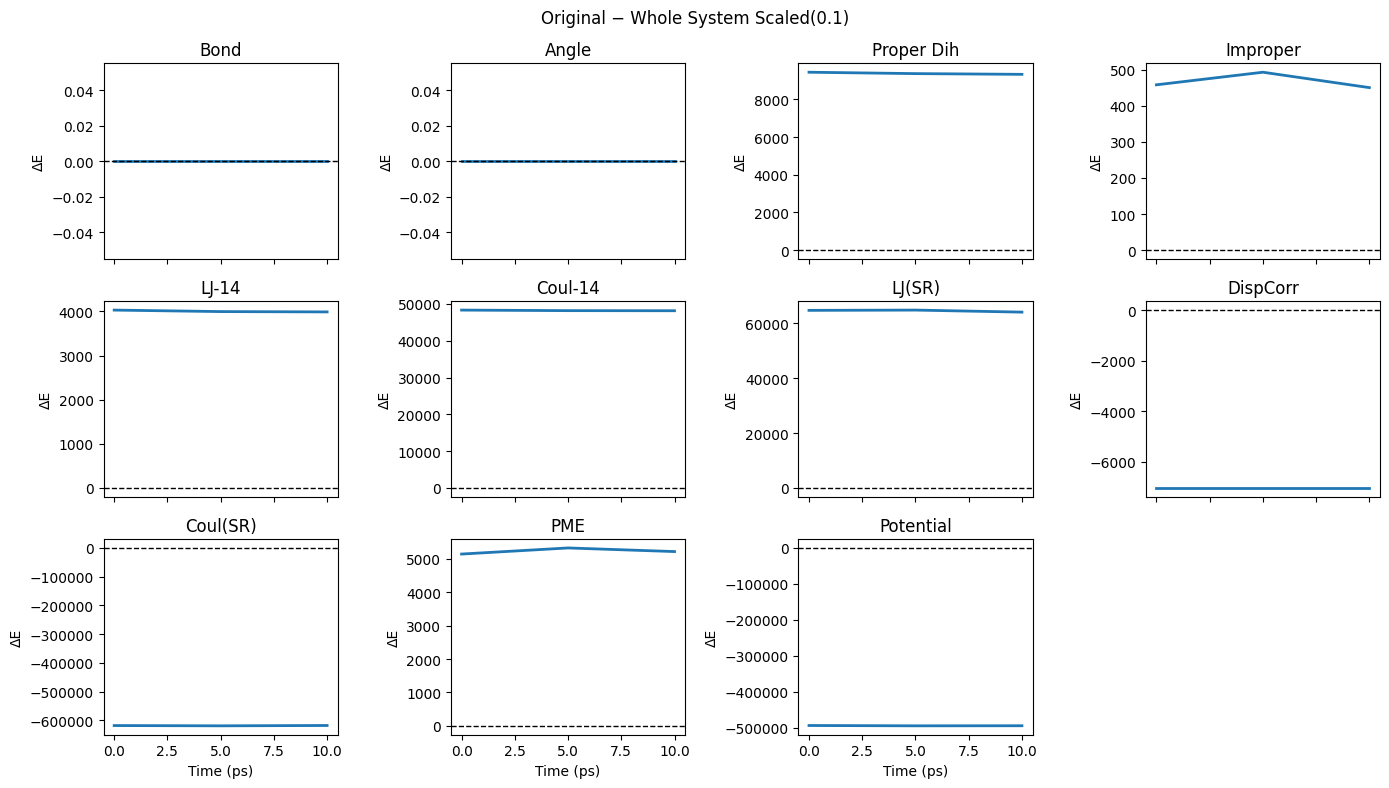

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Bond", "Angle", "Proper Dih", "Improper",
    "LJ-14", "Coul-14", "LJ(SR)", "DispCorr",
    "Coul(SR)", "PME", "Potential"
]

ene = pd.read_csv("2b/rerun0/energy.xvg", header=None, sep=r"\s+")
ene_scaled = pd.read_csv("2b/rerun_whole/energy.xvg", header=None, sep=r"\s+")

time = ene.iloc[:,0]
diff = ene.iloc[:,1:].values - ene_scaled.iloc[:,1:].values

fig, axes = plt.subplots(3,4,figsize=(14,8),sharex=True)
axes = axes.flatten()

for i,name in enumerate(labels):
    axes[i].plot(time,diff[:,i],lw=2)
    axes[i].axhline(0,color="black",ls="--",lw=1)
    axes[i].set_title(name)
    axes[i].set_ylabel("ΔE")

for j in range(len(labels),12):
    axes[j].axis("off")

for ax in axes[-4:]:
    ax.set_xlabel("Time (ps)")

fig.suptitle("Original − Whole System Scaled(0.1)")
plt.tight_layout()
plt.show()

### 🔍 Whole-System Scaling Check

Applied:

```text
partial_tempering(0.1)
```

Observed:

✅ Bond / Angle unchanged  
✅ Dihedral, LJ, Coulomb scaled  
✅ Potential changed strongly  

Inference:

```text
Whole-system Hamiltonian scaling works correctly
```

# 2c: Sanity check on replica-exchange implementation

Once we know the topologies are fine, we should double check if the gromacs+plumed implementation is correctly calculating the acceptance.

We run a replica exchange simulation with 2 replicas with identical Hamiltonians. Acceptance shoud be 1.

In [14]:
import os
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(cmd, shell=True, executable="/bin/bash", check=True)

os.makedirs("2c/rep0", exist_ok=True)
os.makedirs("2c/rep1", exist_ok=True)

open("2c/plumed.dat", "w").close()

run("cp 2b/topol_scaled1.0.top 2c/topol_scaled1.0.top")

run("cd 2c/rep0 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr")

run("cd 2c/rep1 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../topol_scaled1.0.top -o topol.tpr")

run("cd 2c && mpirun --oversubscribe -np 2 gmx_mpi mdrun -nsteps 1000 -multidir rep0 rep1 -replex 200 -hrex -plumed ../plumed.dat -nb cpu -pme cpu -bonded cpu -ntomp 1")

cp 2b/topol_scaled1.0.top 2c/topol_scaled1.0.top
cd 2c/rep0 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2c/rep0
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file ../../grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Kissing You is Like Kissing Gravel" (Throwing Mus

Setting the LD random seed to -163943430

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2c/rep1
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../topol_scaled1.0.top -o topol.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file ../../grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Never attribute to malice that which can b

Setting the LD random seed to -77202193

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimen

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2c
Command line:
  gmx_mpi mdrun -nsteps 1000 -multidir rep0 rep1 -replex 200 -hrex -plumed ../plumed.dat -nb cpu -pme cpu -bonded cpu -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.

Overriding nsteps with value passed on the command line: 1000 steps, 2 ps
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance 

In [16]:
logfile = "2c/rep0/md.log"

patterns = ["Repl", "dplumed"]

with open(logfile) as f:
    lines = f.readlines()

for pattern in patterns:
    print(f"\n===== {pattern} =====")
    for line in lines:
        if pattern == "dplumed":
            if line.startswith("dplumed"):
                print(line.rstrip())
        else:
            if pattern in line:
                print(line.rstrip())


===== Repl =====
Initializing Replica Exchange
Repl  There are 2 replicas:
Replica-exchange molecular dynamics method for protein folding
Replica exchange in temperature
Replica exchange interval: 200
Replica random seed: -271396
Replica exchange information below: ex and x = exchange, pr = probability
Replica exchange at step 200 time 0.40000
Repl 0 <-> 1  dE_term = -0.000e+00 (kT)
Repl ex  0 x  1
Repl pr   1.0
Replica exchange at step 400 time 0.80000
Repl ex  0    1
Repl pr
Replica exchange at step 600 time 1.20000
Repl 0 <-> 1  dE_term = -0.000e+00 (kT)
Repl ex  0 x  1
Repl pr   1.0
Replica exchange at step 800 time 1.60000
Repl ex  0    1
Repl pr
Replica exchange statistics
Repl  4 attempts, 2 odd, 2 even
Repl  average probabilities:
Repl     0    1
Repl      1.0
Repl  number of exchanges:
Repl     0    1
Repl        2
Repl  average number of exchanges:
Repl     0    1
Repl      1.0
Repl        Empirical Transition Matrix
Repl       1       2
Repl  0.5000  0.5000  0
Repl  0.5000 

### 🔍 Replica Exchange Sanity Check

Observed:

✅ Exchange probability = 1.0  
✅ Exchanges accepted every attempt  
✅ dE_term ≈ 0 kT  
✅ dplumed ~ 10⁻⁶–10⁻⁸ kT  

Inference:

```text
Replica exchange acceptance is implemented correctly
```

Identical Hamiltonians give ~100% acceptance as expected.

## 🧪 Test λ Spacing and Potential-Energy Overlap

Prepares **30 λ replicas from 1.00 to 0.30** to test whether neighboring replicas show sufficient **potential-energy overlap** and to evaluate whether the chosen λ spacing is suitable for efficient replica exchange.

In [17]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd,flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00,0.30,30)

os.makedirs("2d",exist_ok=True)

def prep_lambda(lam):

    label = int(round(lam*100))
    path = f"2d/lambda_{label}"

    os.makedirs(path,exist_ok=True)

    run(f"cp 2a/processed_selected.top {path}/processed_selected.top")

    run(
        f"cd {path} && "
        f"plumed partial_tempering {lam:.3f} < processed_selected.top > topol.top"
    )

    run(
        f"cd {path} && "
        f"gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1"
    )

    return f"✅ lambda_{label}"

workers=len(lambdas)

with ThreadPoolExecutor(max_workers=workers) as executor:

    futures=[
        executor.submit(prep_lambda,lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        print(future.result(),flush=True)

print("🎉 Finished prep")

cp 2a/processed_selected.top 2d/lambda_100/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_90/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_98/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_78/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_95/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_93/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_35/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_88/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_86/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_83/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_81/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_76/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_73/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_71/processed_selected.top
cd 2d/lambda_90 && plumed partial_tempering 0.903 < processed_selected.top > topol.top
cd

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_83
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_81
Command line:
  gmx_mpi g

Setting the LD random seed to -874021191

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------

Setting the LD random seed to -1065017

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38
               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_52
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5

NOTE 3 [file ../../gro

Setting the LD random seed to -594038862

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------

Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer f

...

Setting the LD random seed to 2003457982

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------

Setting the LD random seed to -390595098

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 

Generating 1-4 interactions: fudge = 0.5

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.


NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38
Generating 1-4 interactions: fudge = 0.5

NOTE 2 [file topol.top, line 57639]:
  System has non-zero total charge: 1.006262
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file topol.top, line 57639]:
  You are using Ewald electrostatics in a system with 

Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 60x72x64, spacing 0.112 0.117 0.116

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

GROMACS reminds you: "Perfect is the enemy of good." (Voltaire)

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

GROMACS reminds you: "Perfect is the enemy of good." (Voltaire)


NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 3 NOTEs

There was 1 WARNING
Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

GROMACS reminds you: "Perfect is the enemy of good." (Voltaire)


GROMACS reminds you: "Perfect is the enemy of good." (Voltaire)


GROMACS reminds you: "Perfect is the enemy of good." (Voltaire)


NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 3 NOTEs

There was 1 WARN

Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 60x72x64, spacing 0.112 0.117 0.116

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance

## 🚀 Run 10 ns Sampling Across All λ Windows

Runs all **30 λ windows simultaneously for 10 ns**, distributed across four GPUs, to generate the initial trajectories used to evaluate **RMSD, radius of gyration, and potential-energy overlap** across the λ range.

> **Note:** this command does not perform replica exchange because no `-replex` option is specified; it runs the 30 λ windows in parallel.

In [18]:
import os
import subprocess
import numpy as np

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:

    label = int(round(lam * 100))
    dirs.append(f"2d/lambda_{label}")

multidir = " ".join(dirs)

run(
    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-nsteps 5000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"
)

print("🎉 Finished all lambdas")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -nsteps 5000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -nsteps 5000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading 

🎉 Finished all lambdas


## ⏳ Extend Sampling to 100 ns

As observed previously for the **3PRG and 6ONJ test runs**, the initial **10 ns sampling was insufficient** to clearly assess convergence, and the potential-energy distributions remained noisy. The same approach was therefore applied here: all 30 λ windows were continued from their checkpoints for an additional **90 ns**, bringing the total sampling time to **100 ns per window** for a more reliable evaluation of RMSD, radius of gyration, and potential-energy overlap.

In [ ]:
import os
import subprocess
import numpy as np

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:
    label = int(round(lam * 100))
    dirs.append(f"2d/lambda_{label}")

multidir = " ".join(dirs)

run(
    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-cpi topol.cpt "
    f"-append "
    f"-nsteps 45000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"
)

print("🎉 Continued all lambdas by 90 ns")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 45000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 45000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (si

## ⏳ Continue All λ Windows to 100 ns

Continues all **30 λ windows from their existing checkpoints** until they reach a total of **100 ns sampling**. This extended run provides the longer trajectories needed to more reliably evaluate **RMSD, radius of gyration, and potential-energy overlap** across the λ range.

In [4]:
import os
import subprocess
import numpy as np

def clean_env():

    for k in list(os.environ):

        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):

    clean_env()

    print(cmd, flush=True)

    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:

    label = int(round(lam * 100))

    dirs.append(
        f"2d/lambda_{label}"
    )

multidir = " ".join(dirs)

run(

    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-cpi topol.cpt "
    f"-append "
    f"-nsteps 50000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"

)

print("🎉 Continued all lambdas to 100 ns total")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 50000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 50000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (si

KeyboardInterrupt: 

## 🔧 Complete Any Remaining λ Windows to 100 ns

Checks the checkpoint time for each λ window and identifies any simulations that are still below **100 ns**. Only incomplete replicas are continued for the remaining simulation time, while replicas that have already reached 100 ns are skipped.

In [6]:
import os
import re
import subprocess
import numpy as np

TARGET_PS = 100000.0
DT_PS = 0.002

lambdas = np.linspace(1.00, 0.30, 30)

for lam in lambdas:
    label = int(round(lam * 100))
    d = f"2d/lambda_{label}"
    cpt = f"{d}/topol.cpt"

    if not os.path.exists(cpt):
        print(f"❌ Missing {cpt}")
        continue

    out = subprocess.check_output(
        f"gmx_mpi check -f {cpt}",
        shell=True,
        executable="/bin/bash",
        text=True,
        stderr=subprocess.STDOUT
    )

    m = re.search(r"time\s+([\d\.]+)", out)

    if not m:
        print(f"❌ Could not read time for {d}")
        continue

    current_ps = float(m.group(1))

    if current_ps >= TARGET_PS:
        print(f"✅ Skipping {d}: already {current_ps/1000:.2f} ns")
        continue

    remaining_ps = TARGET_PS - current_ps
    nsteps = int(round(remaining_ps / DT_PS))

    print(f"▶️ Continuing {d}: {current_ps/1000:.2f} → 100.00 ns")

    subprocess.run(
        f"cd {d} && "
        f"mpirun --oversubscribe -np 1 "
        f"gmx_mpi mdrun "
        f"-deffnm topol "
        f"-cpi topol.cpt "
        f"-append "
        f"-nsteps {nsteps} "
        f"-nb gpu "
        f"-pme gpu "
        f"-bonded gpu "
        f"-pin auto "
        f"-ntomp 1",
        shell=True,
        executable="/bin/bash",
        check=True
    )

print("🎉 Only replicas below 100 ns were completed to 100 ns")

▶️ Continuing 2d/lambda_100: 98.29 → 100.00 ns


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_100
Command line:
  gmx_mpi mdrun -deffnm topol -cpi topol.cpt -append -nsteps 852719 -nb gpu -pme gpu -bonded gpu -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Overriding nsteps with value passed on the command line: 852719 steps, 1.71e+03 ps
Changing nstlist from 10 to 80, rlist from 0.9 to 1.039


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) shor

▶️ Continuing 2d/lambda_98: 97.99 → 100.00 ns


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_98
Command line:
  gmx_mpi mdrun -deffnm topol -cpi topol.cpt -append -nsteps 1002879 -nb gpu -pme gpu -bonded gpu -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Overriding nsteps with value passed on the command line: 1002879 steps, 2.01e+03 ps
Changing nstlist from 10 to 80, rlist from 0.9 to 1.039


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) sho

✅ Skipping 2d/lambda_95: already 100.90 ns
▶️ Continuing 2d/lambda_93: 99.51 → 100.00 ns


...

▶️ Continuing 2d/lambda_88: 94.25 → 100.00 ns


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88
Command line:
  gmx_mpi mdrun -deffnm topol -cpi topol.cpt -append -nsteps 2873199 -nb gpu -pme gpu -bonded gpu -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Overriding nsteps with value passed on the command line: 2873199 steps, 5.75e+03 ps
Changing nstlist from 10 to 80, rlist from 0.9 to 1.038


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) sho

✅ Skipping 2d/lambda_86: already 102.29 ns
✅ Skipping 2d/lambda_83: already 103.86 ns
✅ Skipping 2d/lambda_81: already 100.15 ns
▶️ Continuing 2d/lambda_78: 97.48 → 100.00 ns


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_78
Command line:
  gmx_mpi mdrun -deffnm topol -cpi topol.cpt -append -nsteps 1257679 -nb gpu -pme gpu -bonded gpu -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Overriding nsteps with value passed on the command line: 1257679 steps, 2.52e+03 ps
Changing nstlist from 10 to 80, rlist from 0.9 to 1.038


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) sho

✅ Skipping 2d/lambda_76: already 107.40 ns
✅ Skipping 2d/lambda_73: already 106.28 ns
✅ Skipping 2d/lambda_71: already 108.86 ns
✅ Skipping 2d/lambda_69: already 108.93 ns
✅ Skipping 2d/lambda_66: already 101.18 ns
✅ Skipping 2d/lambda_64: already 101.07 ns
✅ Skipping 2d/lambda_61: already 106.59 ns
✅ Skipping 2d/lambda_59: already 106.74 ns
✅ Skipping 2d/lambda_57: already 121.03 ns
✅ Skipping 2d/lambda_54: already 118.25 ns
✅ Skipping 2d/lambda_52: already 118.72 ns
✅ Skipping 2d/lambda_49: already 118.73 ns
✅ Skipping 2d/lambda_47: already 116.00 ns
✅ Skipping 2d/lambda_44: already 121.01 ns
✅ Skipping 2d/lambda_42: already 112.74 ns
✅ Skipping 2d/lambda_40: already 112.03 ns
✅ Skipping 2d/lambda_37: already 116.68 ns
✅ Skipping 2d/lambda_35: already 114.85 ns
✅ Skipping 2d/lambda_32: already 113.47 ns
✅ Skipping 2d/lambda_30: already 107.33 ns
🎉 Only replicas below 100 ns were completed to 100 ns


## 📊 Calculate RMSD and Radius of Gyration for All λ Windows

Calculates **RMSD** and **radius of gyration (Rg)** for all **30 λ windows** using the completed 100 ns trajectories. These measurements are used to reassess structural deviation and compactness across the λ range after the extended sampling.

In [4]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_lambda(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(workdir, "2d", f"lambda_{label}")

    tpr = os.path.join(replica_dir, "topol.tpr")
    xtc = os.path.join(replica_dir, "topol.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ lambda_{label}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ lambda_{label}: missing topol.xtc"

    print(f"▶️ Starting lambda_{label}", flush=True)

    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished lambda_{label}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambdas at once
max_workers = len(lambdas)

# ============================================================
# Run analysis in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_lambda, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting lambda_90
▶️ Starting lambda_98
▶️ Starting lambda_88
▶️ Starting lambda_86
▶️ Starting lambda_83
▶️ Starting lambda_93
▶️ Starting lambda_81
▶️ Starting lambda_71
▶️ Starting lambda_95
▶️ Starting lambda_59
▶️ Starting lambda_100
▶️ Starting lambda_61
▶️ Starting lambda_54
▶️ Starting lambda_76
▶️ Starting lambda_66
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88/gyration.xvg"
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_98/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_98/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_98/gyration.xvg"
printf "1\n" | gmx_mp

               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi gyrate -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_47/topol.xtc -s /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_47/topol.tpr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_47/gyration.xvg

Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_47/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_47/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 42071 elements
Group     1 (        Protein) has  4422 elements
Group  

Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_90/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_90/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_90/rmsd.xvg"


Reading frame   21000 time 105000.000   

GROMACS reminds you: "The best part of winter in Stockholm is going to Australia" (Mark Abraham)

Reading frame   20000 time 100000.000   

GROMACS reminds you: "The best part of winter in Stockholm is going to Australia" (Mark Abraham)



GROMACS reminds you: "The best part of winter in Stockholm is going to Australia" (Mark Abraham)



Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_88/rmsd.xvg"
Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_81/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_81/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_81/rmsd.xvg"


...

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_54




GROMACS reminds you: "I will not be a lemming and follow the crowd over the cliff and into the C." (John Beidler)

Reading frame   24000 time 120000.000   

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_57




GROMACS reminds you: "If at first you don't succeed, try two more times so that your failure is statistically significant." (Dallas Warren)



GROMACS reminds you: "If at first you don't succeed, try two more times so that your failure is statistically significant." (Dallas Warren)



Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_44

🎉 Finished all parallel Rg and RMSD analysis.


## 📈 Visualize RMSD and Radius of Gyration Across λ Windows

Plots **RMSD** and **radius of gyration (Rg)** for all **30 λ windows** over the 100 ns trajectories. The plots are used to compare how increasing tempering expands structural sampling across the λ range and to identify the λ regime where RMSD reaches the **~1.5 nm range associated with the intermediate conformations** observed in the urea and SMOG simulations.

Valid lambdas: [100, 98, 95, 93, 90, 88, 86, 83, 81, 78, 76, 73, 71, 69, 66, 64, 61, 59, 57, 54, 52, 49, 47, 44, 42, 40, 37, 35, 32, 30]


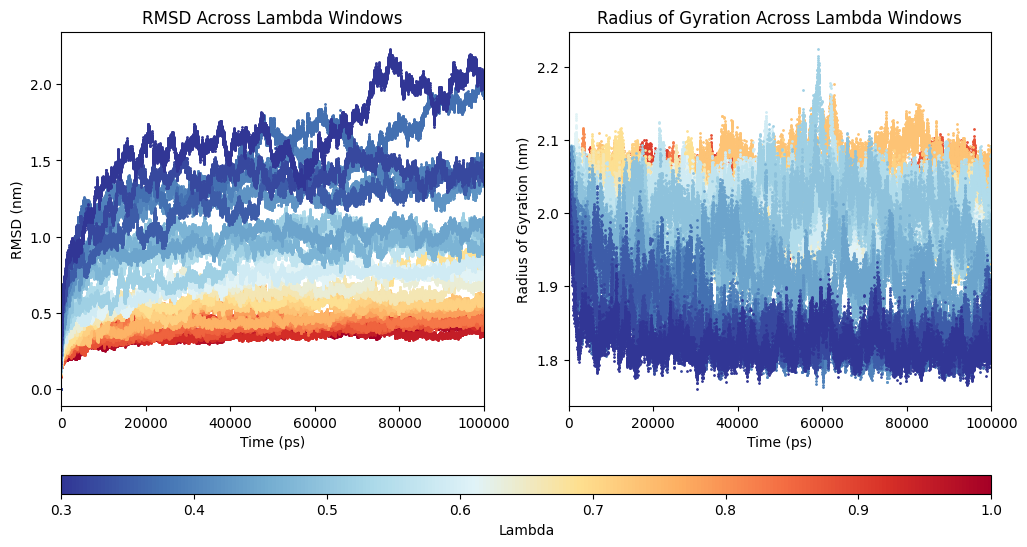

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# LAMBDAS
# =========================================================

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

norm = Normalize(vmin=min(lambdas), vmax=max(lambdas))

main_dir = "2d"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_lambdas = []
valid_labels = []

for lam, label in zip(lambdas, labels):

    rmsd_file = os.path.join(main_dir, f"lambda_{label}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"lambda_{label}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for lambda_{label}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_lambdas.append(lam)
    valid_labels.append(label)

print("Valid lambdas:", valid_labels)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Lambda Windows")
ax1.set_xlim(0, 100000)

# =========================================================
# Rg
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Lambda Windows")
ax2.set_xlim(0, 100000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Lambda")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## ⚡ Extract Potential Energy Across λ Windows

Extracts the **potential-energy time series** from all **30 λ windows** after 100 ns of sampling. These distributions are used to evaluate **energetic overlap between neighboring λ windows** and assess whether the selected λ spacing is appropriate for replica exchange.

In [6]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  2d/lambda_XXX/topol.edr
#   Output: 2d/lambda_XXX/potential.xvg
# ============================================================

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(main_dir, f"lambda_{label}")

    edr_file = os.path.join(replica_dir, "topol.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ lambda_{label}: missing topol.edr"

    print(f"▶️ Starting lambda_{label}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ lambda_{label}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "2d")

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambda windows at once
max_workers = len(lambdas)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all lambda windows.")

▶️ Starting lambda_100
▶️ Starting lambda_98
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_100/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_100/potential.xvg" -xvg none
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_98/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_98/potential.xvg" -xvg none
▶️ Starting lambda_95
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_95/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_95/potential.xvg" -xvg none
▶️ Starting lambda_93
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_93/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_P

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_35/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_35/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_35/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 57435001 steps [ 0.0000 through 114870.0000 ps ], 1 data sets
All statistics are over 574351 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -504556         15    780.611    14.0987  (kJ/mol)

Statistics over 59370001 steps [ 0.0000 through 118740.0000 ps ], 1 data sets
All statistics are over 593701 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -511566        5.5     781.89   -18.6979  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_93/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_93/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_93/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  

✅ lambda_35: potential.xvg written, 11488 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -533777         23    785.159   -168.073  (kJ/mol)
✅ lambda_49: potential.xvg written, 11875 frames

Statistics over 53670001 steps [ 0.0000 through 107340.0000 ps ], 1 data sets
All statistics are over 536701 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -502332        9.6    777.048   -44.0538  (kJ/mol)
✅ lambda_93: potential.xvg written, 10001 frames


...


Statistics over 50540001 steps [ 0.0000 through 101080.0000 ps ], 1 data sets
All statistics are over 505401 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -518920         24    784.011   -170.528  (kJ/mol)
✅ lambda_64: potential.xvg written, 10109 frames

Statistics over 53380001 steps [ 0.0000 through 106760.0000 ps ], 1 data sets
All statistics are over 533801 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -516421         23    784.464    -155.96  (kJ/mol)

Statistics over 53705001 steps [ 0.0000 through 107410.0000 ps ], 1 data sets
All statistics are over 537051 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
------------------------------------------------------------------------

Reading energy frame   3000 time 30000.000                        :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_61/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_61/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/2d/lambda_61/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.

✅ lambda_95: potential.xvg written, 10092 frames

Statistics over 59365001 steps [ 0.0000 through 118730.0000 ps ], 1 data sets
All statistics are over 593651 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -512746         13    781.424   -47.1158  (kJ/mol)
✅ lambda_32: potential.xvg written, 11350 frames

Statistics over 59135001 steps [ 0.0000 through 118270.0000 ps ], 1 data sets
All statistics are over 591351 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -513939         19    782.413   -108.461  (kJ/mol)
✅ lambda_88: potential.xvg written, 10001 frames
✅ lambda_90: potential.xvg written, 10001 frames

Statistics over 50595001 steps [ 0.0000 through 101190.0000 ps ], 1 data sets
All statistics are over 505951 po

Reading energy frame   7000 time 70000.000         
GROMACS reminds you: "Yeah, uh uh, Neil's Head !" (Neil)

Last energy frame read 10894 time 108940.000         

GROMACS reminds you: "Yeah, uh uh, Neil's Head !" (Neil)

Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "Yeah, uh uh, Neil's Head !" (Neil)

Last energy frame read 10000 time 100000.000         
Reading energy frame  10000 time 100000.000         
GROMACS reminds you: "Yeah, uh uh, Neil's Head !" (Neil)

Last energy frame read 11205 time 112050.000         

GROMACS reminds you: "Yeah, uh uh, Neil's Head !" (Neil)



✅ lambda_61: potential.xvg written, 10661 frames
✅ lambda_98: potential.xvg written, 10001 frames
✅ lambda_40: potential.xvg written, 11206 frames

🎉 Finished extracting potential energy for all lambda windows.


## ⚡ Visualize Potential-Energy Overlap Across λ Windows

Plots the **potential-energy distributions** for all **30 λ windows** after 100 ns of sampling. The overlap between neighboring distributions is used to assess whether the chosen **λ spacing provides sufficient energetic overlap for efficient replica exchange**.

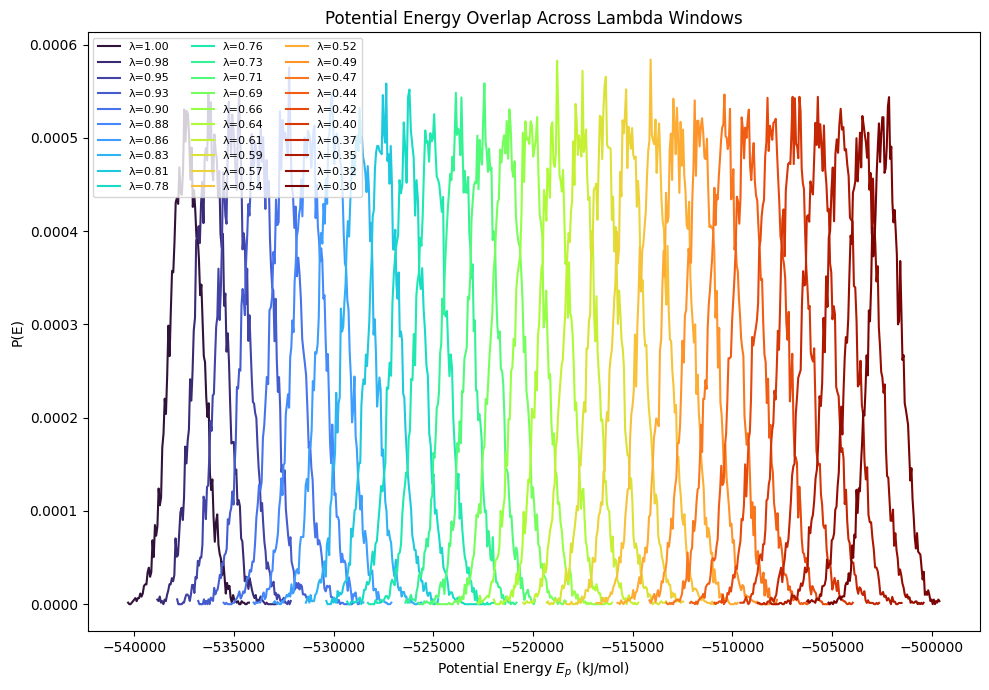

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  2d/lambda_XXX/potential.xvg
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(main_dir, f"lambda_{label}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap Across Lambda Windows")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## ⚡ Inspect Potential-Energy Overlap Using Alternate λ Windows

Plots **every second λ window** to reduce crowding and make the **potential-energy overlap between neighboring regions of the λ range easier to visualize**. This provides a clearer assessment of whether the λ range and spacing are suitable for designing the expanded replica ladder.

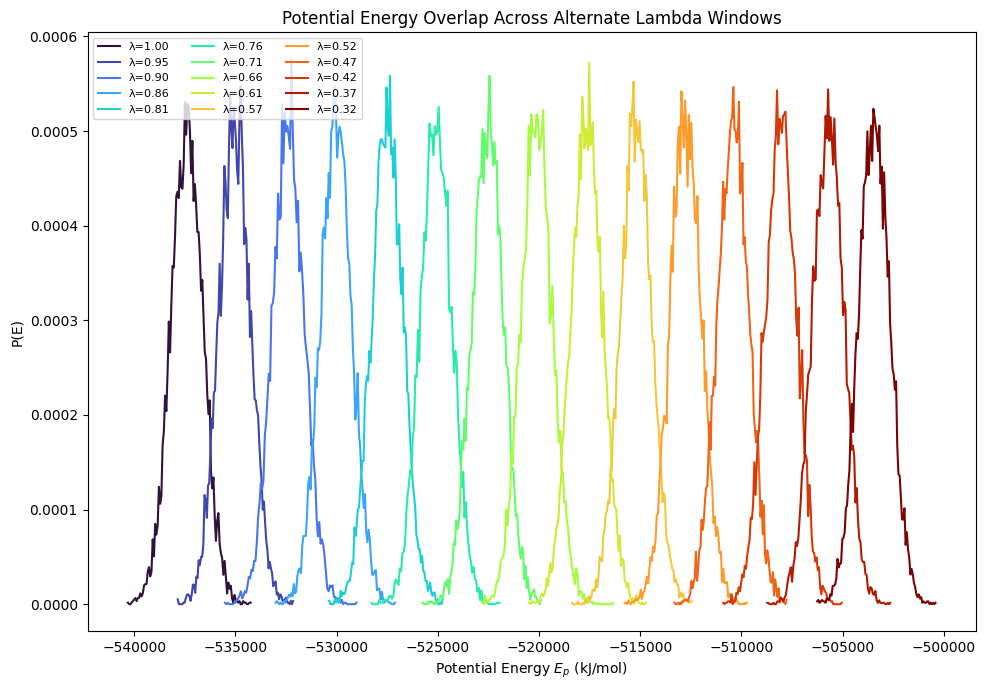

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Alternate lambda windows only
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)[::2]
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(
        main_dir,
        f"lambda_{label}",
        "potential.xvg"
    )

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    centers = 0.5 * (
        edges[:-1] +
        edges[1:]
    )

    plt.plot(
        centers,
        pdf,
        lw=1.5,
        color=colors[i],
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title(
    "Potential Energy Overlap Across Alternate Lambda Windows"
)

plt.legend(
    fontsize=8,
    ncol=3
)

plt.tight_layout()
plt.show()

### 🔎 Inference After 100 ns

After 100 ns, the neighboring λ windows show **substantial potential-energy overlap**, supporting the selected λ range and spacing for replica exchange. Increasing tempering progressively broadens the conformational sampling, with the lower λ replicas reaching **RMSD values >1 nm and up to ~2 nm**, while the radius of gyration remains relatively constrained. This is encouraging because the replicas are exploring conformations far from the starting structure without obvious global expansion of the protein. The highly displaced states may therefore represent **intermediate or partially unfolded conformations**, similar to those sampled in the urea and SMOG simulations, although this will require structural analysis to confirm. 

Overall, this test provides a **blueprint for selecting the λ range** for the expanded 64-replica setup with replica exchange. In particular, the RMSD profiles identify the λ regime where sampling begins to cross **~1.5 nm RMSD**, a range associated with the intermediate/partially unfolded conformations observed in the urea and SMOG simulations. This λ range will therefore guide the design of the denser 64-replica ladder to better sample these states.
*******

### 🎬 Bonus: Visual Inspection of Low-λ Trajectories

Because the low-λ replicas reach RMSD values of approximately **1.5 nm**, similar to the intermediate conformations observed in the **urea and SMOG simulations**, trajectories at **λ = 0.52 and 0.40** were visualized to assess whether they show comparable structural features.

In [10]:
!echo 1 1 | gmx_mpi trjconv -f 2d/lambda_52/topol.xtc -s 2d/lambda_52/topol.tpr -center -pbc mol -skip 50 -o 2d/lambda_52/lambda_52_movie.pdb

!echo 1 1 | gmx_mpi trjconv -f 2d/lambda_40/topol.xtc -s 2d/lambda_40/topol.tpr -center -pbc mol -skip 50 -o 2d/lambda_40/lambda_40_movie.pdb

               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi trjconv -f 2d/lambda_52/topol.xtc -s 2d/lambda_52/topol.tpr -center -pbc mol -skip 50 -o 2d/lambda_52/lambda_52_movie.pdb

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write pdb: Protein data bank file
Reading file 2d/lambda_52/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 2d/lambda_52/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Select group for centering
Group     0 (         System) has 42071 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5